## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** BAI,Yongqi

**Date:** 2026/10/14

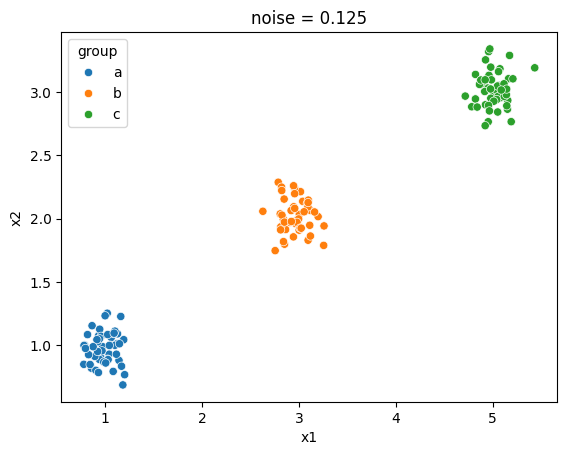

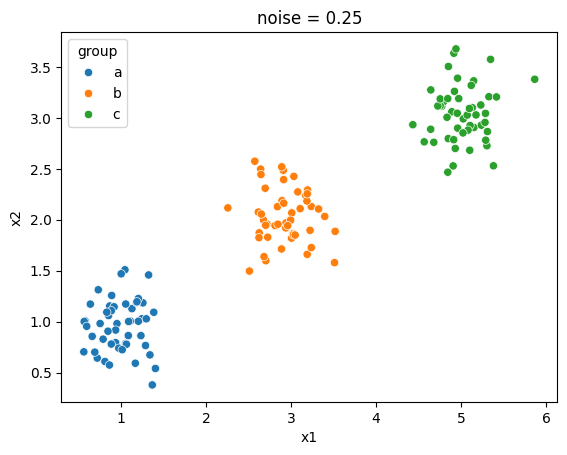

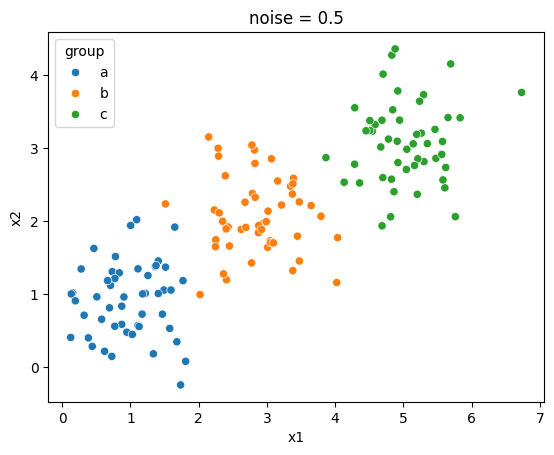

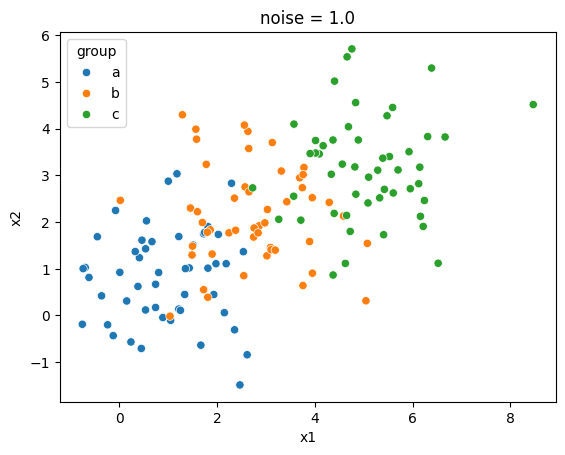

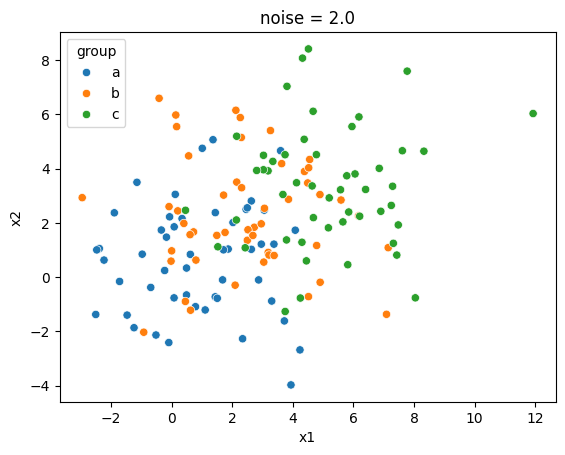

noise 0.125 | SSE for k = 1 to 5: [511.6 128.9   4.9   4.3   3.8]
noise 0.25 | SSE for k = 1 to 5: [533.3 142.7  19.7  17.3  15.2]
noise 0.5 | SSE for k = 1 to 5: [606.6 186.8  77.8  67.2  58.7]
noise 1.0 | SSE for k = 1 to 5: [873.7 361.6 254.9 212.6 175.5]
noise 2.0 | SSE for k = 1 to 5: [1889.2 1071.8  792.3  591.2  501.9]


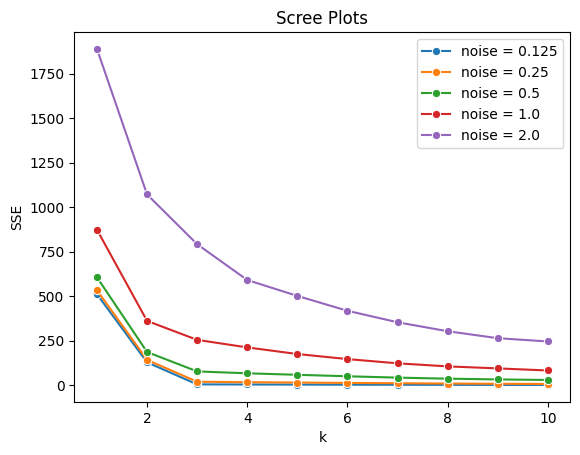

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) 
    
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

# Q1.2
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]
for i in range(len(datasets)):
    sns.scatterplot(data=datasets[i], x='x1', y='x2', hue='group').set_title('noise = ' + str(noises[i]))
    plt.show()

# Q1.3

ks = np.arange(1, 11)
for i in range(len(datasets)):
    X = datasets[i].loc[:, ['x1', 'x2']]
    SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
    print('noise', noises[i], '| SSE for k = 1 to 5:', np.round(SSE[:5], 1))
    sns.lineplot(x=ks, y=SSE, marker='o', label='noise = ' + str(noises[i]))
plt.title('Scree Plots')
plt.xlabel('k')
plt.ylabel('SSE')
plt.show()

2. As the noise grows, the groups get harder to tell apart. At 0.125 and 0.25 they are tight and far apart, at 0.5 their edges come close, at 1.0 they overlap, and at 2.0 they merge into one cloud.

3. At low noise the scree plot has a sharp elbow at k = 3, so k = 3 is an easy choice. The elbow fades as the noise grows. At 1.0 the clearest bend moves to k = 2 even though there are three groups, and at 2.0 the curve falls smoothly with no elbow, so no k stands out. SSE is also larger at higher noise, rising from 511.6 to 1889.2 at k = 1.

4. SSE always falls as k grows, so it cannot choose k by itself. While k is below the true number of groups, each new cluster splits apart groups that were lumped together, and SSE falls a lot. Once k passes that number, a new cluster can only split a real group, and SSE barely moves. At noise 0.125, SSE falls from 511.6 to 128.9 to 4.9 as k goes from 1 to 3, then only to 4.3 at k = 4. The elbow is where the big drops turn into small ones. With heavy noise the groups overlap, the two kinds of drops look alike, and the elbow disappears.

(148, 7)
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


,index,Year,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
count,148.000000,148.0,148.000000,148.000000,148.000000,148.000000
mean,2831.256757,2020.0,13153.747670,0.019619,0.061510,268.264494
std,1654.299355,0.0,68005.236120,0.015033,0.046207,430.434878
min,32.000000,2020.0,8.622460,0.000054,0.004896,0.580129
25%,1409.000000,2020.0,204.877177,0.010413,0.031352,20.553464
50%,2871.000000,2020.0,959.535443,0.015324,0.047402,81.506703
75%,4222.500000,2020.0,5289.998320,0.024327,0.084681,326.267753
max,5880.000000,2020.0,778397.200000,0.098470,0.303027,2520.398541


count    148.000000
mean       0.349520
std        0.132363
min        0.002851
25%        0.258576
50%        0.338406
75%        0.448049
max        0.746975
Name: implied gov share of GDP, dtype: float64


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,implied gov share of GDP
5880,5880,2020,Zimbabwe,8.622460,0.000054,0.018941,0.580129,0.002851
406,406,2020,Belarus,707.418033,0.011742,0.303027,74.866974,0.038748


SSE for k = 1 to 6: [5.411 2.435 1.322 0.629 0.415 0.311]


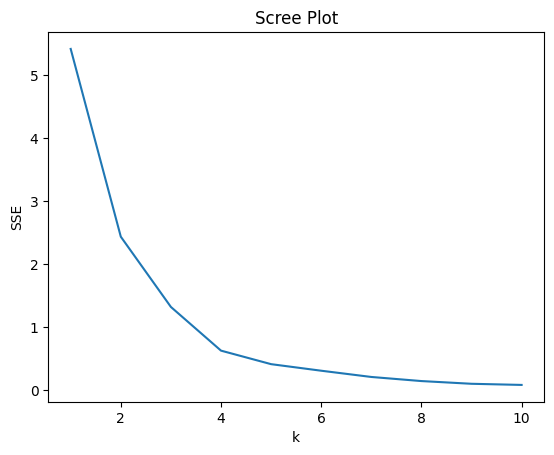

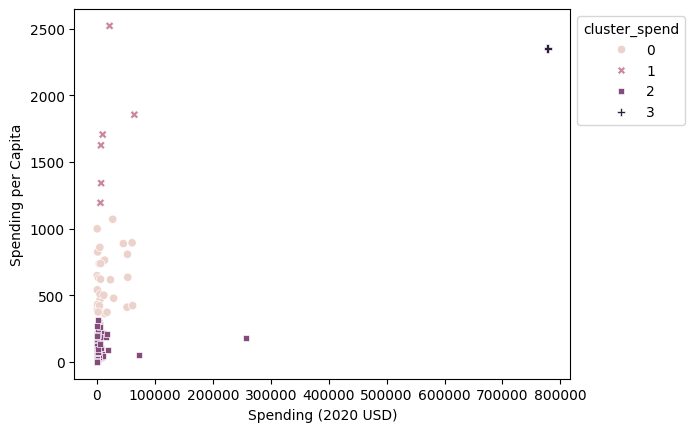

                       Country  Spending (2020 USD)  Spending per Capita  \
1052                     China        257973.429834           179.232355   
5540  United States of America        778397.200000          2351.631858   

      cluster_spend  
1052              2  
5540              3  
cluster 0 ['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brunei', 'Canada', 'Cyprus', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Italy', 'Japan', 'Korea, South', 'Latvia', 'Lithuania', 'Luxembourg', 'Netherlands', 'New Zealand', 'Poland', 'Portugal', 'Russia', 'Slovakia', 'Spain', 'Sweden', 'Switzerland', 'Taiwan', 'United Kingdom']
cluster 1 ['Israel', 'Kuwait', 'Norway', 'Oman', 'Saudi Arabia', 'Singapore']
cluster 3 ['United States of America']


Spending (2020 USD)                                              \
                            count           mean           std            min   
cluster_spend                                                                   
0                            30.0   17077.591354  20583.053357     405.790494   
1                             6.0   19443.362047  22861.507114    6095.708713   
2                           111.0    4859.185065  25405.739131       8.622460   
3                             1.0  778397.200000           NaN  778397.200000   

                                                                           \
                         25%            50%            75%            max   
cluster_spend                                                               
0                2294.039665    5857.060906   26296.001003   61712.537169   
1                7023.251766    8624.225729   18857.070183   64558.400000   
2                 130.010211     382.464677    2297.032353  257973.429834   
3              778397.200000  778397.200000  778397.200000  778397.200000   

              Spending per Capita                                        \
                            count         mean         std          min   
cluster_spend                                                             
0                            30.0   607.478618  206.928757   362.467076   
1                             6.0  1706.721916  466.375705  1193.598730   
2                           111.0    80.061470   83.501824     0.580129   
3                             1.0  2351.631858         NaN  2351.631858   

                                                                   
                       25%          50%          75%          max  
cluster_spend                                                      
0               422.208252   579.004604   757.328513  1070.623322  
1              1412.083201  1665.447478  1817.219993  2520.398541  
2                14.880549    47.056944   125.387558   314.201312  
3              2351.631858  2351.631858  2351.631858  2351.631858

SSE for k = 1 to 6: [6.961 2.927 1.996 1.477 1.083 0.803]


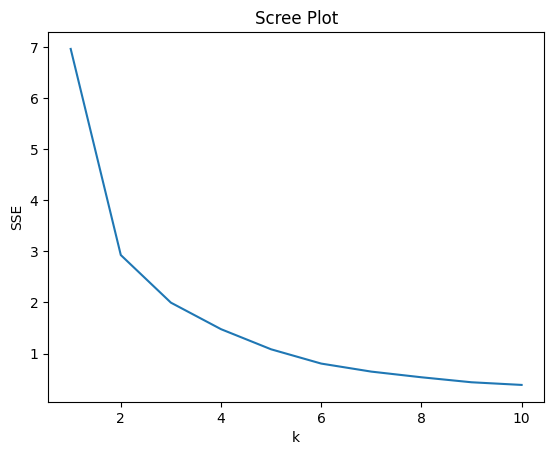

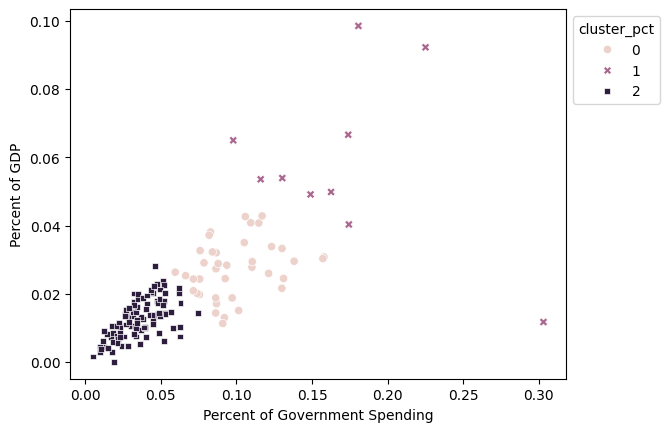

                       Country  Percent of Government Spending  \
1052                     China                        0.047517   
5540  United States of America                        0.081976   

      Percent of GDP  cluster_pct  
1052        0.017988            2  
5540        0.037179            0  
cluster 0 ['Bahrain', 'Bangladesh', 'Botswana', 'Brunei', 'Burkina Faso', 'Burundi', 'Cambodia', 'Central African Republic', 'Chad', 'Chile', 'Colombia', 'Congo, Republic', 'Ecuador', 'Equatorial Guinea', 'Gabon', 'Guinea', 'India', 'Iran', 'Iraq', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Niger', 'Russia', 'Singapore', 'South Sudan', 'Sri Lanka', 'Sudan', 'Taiwan', 'Togo', 'Tunisia', 'Turkey', 'Uganda', 'Ukraine', 'United States of America']
cluster 1 ['Algeria', 'Armenia', 'Azerbaijan', 'Belarus', 'Israel', 'Jordan', 'Kuwait', 'Oman', 'Pakistan', 'Saudi Arabia']


Percent of Government Spending                                \
                                     count      mean       std       min   
cluster_pct                                                                
0                                     39.0  0.098683  0.024125  0.059520   
1                                     10.0  0.171289  0.058725  0.097882   
2                                     99.0  0.035777  0.014549  0.004896   

                                                    Percent of GDP            \
                  25%       50%       75%       max          count      mean   
cluster_pct                                                                    
0            0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1            0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2            0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                         
                  std       min       25%       50%       75%       max  
cluster_pct                                                              
0            0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1            0.024867  0.011742  0.049297  0.053729  0.066190  0.098470  
2            0.005681  0.000054  0.008393  0.013191  0.016752  0.028132

SSE for k = 1 to 6: [12.372  7.71   5.193  4.207  3.258  2.686]


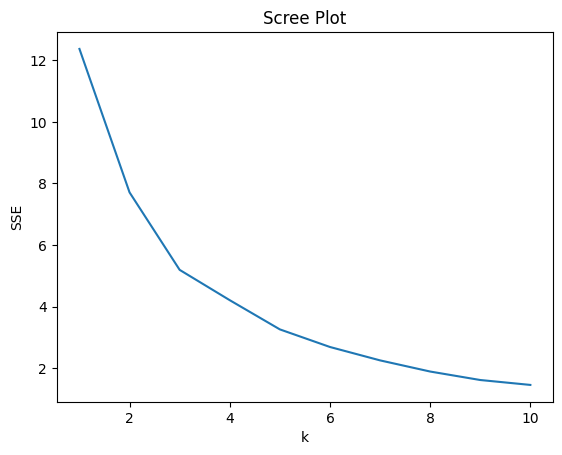

cluster 1 ['Algeria', 'Armenia', 'Azerbaijan', 'Bahrain', 'Belarus', 'Botswana', 'Brunei', 'Burkina Faso', 'Cambodia', 'Chad', 'Colombia', 'Congo, Republic', 'Equatorial Guinea', 'India', 'Iran', 'Iraq', 'Jordan', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Pakistan', 'Russia', 'Taiwan', 'Togo', 'Tunisia', 'Uganda', 'Ukraine']
cluster 2 ['Israel', 'Kuwait', 'Oman', 'Saudi Arabia', 'Singapore', 'United States of America']
cluster_pct   0  1   2
cluster_all           
0            12  0  99
1            25  6   0
2             2  4   0


Spending (2020 USD)                                             \
                          count           mean            std          min   
cluster_all                                                                  
0                         111.0    7086.472777   26479.379918     8.622460   
1                          31.0    8786.086602   17901.909108   162.373364   
2                           6.0  147964.582042  309635.189564  6095.708713   

                                                                     \
                     25%           50%           75%            max   
cluster_all                                                           
0             130.010211    567.650747   3910.107493  257973.429834   
1             467.787851   1404.787234   7739.166193   72937.064048   
2            7700.424616  15897.570598  53872.942442  778397.200000   

            Spending per Capita                                        \
                          count         mean         std          min   
cluster_all                                                             
0                         111.0   196.926833  267.788506     0.580129   
1                          31.0   212.689100  257.841988    18.297119   
2                           6.0  1875.150751  489.800206  1193.598730   

                                                                 \
                     25%          50%          75%          max   
cluster_all                                                       
0              14.880549    67.083417   295.296094  1341.058851   
1              46.485917   135.459845   217.333791   998.966186   
2            1645.301864  1780.059564  2227.318999  2520.398541   

            Percent of Government Spending                                \
                                     count      mean       std       min   
cluster_all                                                                
0                                    111.0  0.040350  0.019320  0.004896   
1                                     31.0  0.122985  0.043927  0.076005   
2                                      6.0  0.135351  0.055392  0.081976   

                                                    Percent of GDP            \
                  25%       50%       75%       max          count      mean   
cluster_all                                                                    
0            0.026712  0.037952  0.050505  0.092044          111.0  0.013419   
1            0.093093  0.114776  0.134663  0.303027           31.0  0.033492   
2            0.101034  0.113271  0.164503  0.225050            6.0  0.062634   

                                                                         
                  std       min       25%       50%       75%       max  
cluster_all                                                              
0            0.005996  0.000054  0.008873  0.013589  0.017769  0.028132  
1            0.011449  0.011742  0.027560  0.032024  0.040531  0.066600  
2            0.028275  0.029429  0.041272  0.059257  0.085398  0.098470

In [2]:
pd.set_option('display.max_columns', None)

# Q2.1
df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df = df.loc[df['Year'] == 2020, :]
df = df.dropna(axis=0)
print(df.shape)
print(df.dtypes)
display(df.describe())

# percent of GDP / percent of government spending = government spending as a share of GDP
df['implied gov share of GDP'] = df['Percent of GDP'] / df['Percent of Government Spending']
print(df['implied gov share of GDP'].describe())
display(df.nsmallest(2, 'implied gov share of GDP'))

# Q2.2
features = ['Spending (2020 USD)', 'Spending per Capita']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
print('SSE for k = 1 to 6:', np.round(SSE[:6], 3))
sns.lineplot(x=ks, y=SSE).set(title='Scree Plot', xlabel='k', ylabel='SSE')
plt.show()

model = KMeans(n_clusters=4, max_iter=300, n_init=10, random_state=0).fit(X)
df['cluster_spend'] = model.labels_
ax = sns.scatterplot(data=df, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster_spend', style='cluster_spend')
sns.move_legend(ax, 'upper left', bbox_to_anchor=(1, 1))
plt.show()

print(df.loc[df['Country'].isin(['United States of America', 'China']), ['Country'] + features + ['cluster_spend']])
for c in range(4):
    members = df.loc[df['cluster_spend'] == c, 'Country']
    if len(members) < 50:
        print('cluster', c, list(members))
display(df.groupby('cluster_spend')[features].describe())

# Q2.3
features = ['Percent of Government Spending', 'Percent of GDP']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
print('SSE for k = 1 to 6:', np.round(SSE[:6], 3))
sns.lineplot(x=ks, y=SSE).set(title='Scree Plot', xlabel='k', ylabel='SSE')
plt.show()

model = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0).fit(X)
df['cluster_pct'] = model.labels_
ax = sns.scatterplot(data=df, x='Percent of Government Spending', y='Percent of GDP', hue='cluster_pct', style='cluster_pct')
sns.move_legend(ax, 'upper left', bbox_to_anchor=(1, 1))
plt.show()

print(df.loc[df['Country'].isin(['United States of America', 'China']), ['Country'] + features + ['cluster_pct']])
for c in range(3):
    members = df.loc[df['cluster_pct'] == c, 'Country']
    if len(members) < 50:
        print('cluster', c, list(members))
display(df.groupby('cluster_pct')[features].describe())

# Q2.4
features = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
print('SSE for k = 1 to 6:', np.round(SSE[:6], 3))
sns.lineplot(x=ks, y=SSE).set(title='Scree Plot', xlabel='k', ylabel='SSE')
plt.show()

model = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0).fit(X)
df['cluster_all'] = model.labels_
for c in range(3):
    members = df.loc[df['cluster_all'] == c, 'Country']
    if len(members) < 50:
        print('cluster', c, list(members))
print(pd.crosstab(df['cluster_all'], df['cluster_pct']))
display(df.groupby('cluster_all')[features].describe())

1. After keeping 2020 and dropping missing values, 148 countries remain. All four variables are already numeric, so no type conversion is needed. Two rows look wrong, though. Percent of GDP divided by percent of government spending gives government spending as a share of GDP, which is 26% to 45% for the middle half of countries but 0.3% for Zimbabwe and 3.9% for Belarus. Belarus's 30% of government spending is probably ten times too high, since 3% would put it in the normal range. I keep both rows to match the 148 countries.

2. The scree plot falls steeply until k = 4 and flattens after, with SSE at 5.41 for k = 1, 0.63 for k = 4 and 0.42 for k = 5, so I use k = 4. The US is a cluster by itself at 778 billion dollars. The other three clusters are levels of spending per person. Israel, Kuwait, Norway, Oman, Saudi Arabia and Singapore have a median of 1,665 dollars per person, a group of 30 mostly European countries has 579, and the other 111 have 47. Total spending only separates the US, because max-min scaling pushes almost every other country near zero on that axis. China spends the second most at 258 billion dollars, but at only 179 dollars per person it lands in the lowest cluster.

3. The elbow is less clear here. SSE is 6.96, 2.93, 2.00 and 1.48 for k = 1 to 4, so the sharpest bend is at k = 2. Since the elbow does not settle it, I choose k by how the clusters will be used and take k = 3, which separates low, middle and high military burden. Ten countries, mostly in the Middle East and the Caucasus, have medians of 16.8% of government spending and 5.4% of GDP, a middle group of 39 has 9.2% and 2.8%, and the other 99 have 3.4% and 1.3%. Unlike part 2, these clusters measure burden rather than size, and the biggest spenders are not the most burdened. The US is no longer alone. At 8.2% of government spending and 3.7% of GDP it sits in the middle group with Russia, India, South Korea and Ukraine, while China and most of Europe are in the lowest group. Belarus is in the top group only because of its doubtful 30%.

4. The elbow is at k = 3, with SSE at 12.37, 7.71, 5.19 and 4.21 for k = 1 to 4. The top cluster is Israel, Kuwait, Oman, Saudi Arabia, Singapore and the US, which spend a lot both per person and as a share of their economy. A middle group of 31, including India, Pakistan, Russia and Ukraine, carries a heavy burden but spends much less per person, with medians of 11.5% of government spending and 135 dollars per person. The other 111 spend little by both measures. The result is closer to part 3, since all 99 countries in the lowest group of part 3 are in the lowest group here. Compared with part 2, the US joins the high per-person group and Norway leaves it because its burden is low.

5. Yes, at a rough level. The clusters separate countries by spending per person, pick out countries where the military takes a large share of the budget, and with all four variables find a small group of rich countries that spend heavily on the military. The limits are clear too. Total spending is so skewed that the US alone sets that axis, which is why China lands in the lowest cluster in part 2. The elbow for the percent variables is soft, so k there is partly a judgment call, and Belarus's doubtful value sets the scale of one axis. The clusters are good for exploring the data but not for firm conclusions.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [3]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]